# Chapter 17: Sequence-to-Sequence Architectures: Encoder-Decoders and Decoders
Character-level encoder-decoder translator


Programs from the book: [_Python for Natural Language Processing_](https://link.springer.com/book/9783031575488)

__Author__: Pierre Nugues

## Download the data

Have a look at the http://www.manythings.org/anki/ site and select a corpus with at least 10,000 pairs. You should understand the target language well. Ideally, it should be your mother tongue.
Then uncomment and run the lines below.

In [66]:
!curl -O http://www.manythings.org/anki/swe-eng.zip
!unzip swe-eng.zip
!mkdir ../datasets/tatoeba
!mv swe.txt ../datasets/tatoeba
!rm swe-eng.zip _about.txt

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed
100 814.6k 100 814.6k   0      0 190.6k      0   00:04   00:04          96954
Archive:  swe-eng.zip
  inflating: _about.txt              
  inflating: swe.txt                 
mkdir: cannot create directory ‘../datasets/tatoeba’: File exists


In [67]:
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

## Modules

In [68]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from torch.optim.lr_scheduler import LambdaLR

from torcheval.metrics.functional import bleu_score

import random
import numpy as np
import math

import matplotlib.pyplot as plt
from tqdm import tqdm
import json

In [69]:
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)

In [70]:
num_samples = 237000 #100000  # Number of samples to train on.
max_len = 120  # max number of characters per sentence

In [71]:
import os

for path in [
    "/usr/lib64",
    "/usr/lib64/libcuda.so.615.78.08",
    "/usr/lib64/libcuda.so.1",
]:
    print(path, "exists:", os.path.exists(path))
    if os.path.isdir(path):
        print("  matching files:",
              [f for f in os.listdir(path) if "libcuda" in f][:20])

if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
DEVICE = torch.device(device)
DEVICE

/usr/lib64 exists: True
  matching files: ['libcuda.so', 'libcuda.so.1', 'libcuda.so.615.78.08', 'libcudadebugger.so.1', 'libcudadebugger.so.615.78.08']
/usr/lib64/libcuda.so.615.78.08 exists: True
/usr/lib64/libcuda.so.1 exists: True


device(type='cuda')

## Dataset

### Creating the pairs

In [72]:
PATH = '../datasets/tatoeba/'

In [73]:
data_file = PATH + 'swe.txt'

In [74]:
with open(data_file, 'r', encoding='utf-8') as f:
    lines = f.read().strip().split('\n')

In [75]:
len(lines)

25666

In [76]:
num_samples = min(num_samples, len(lines))

In [77]:
lines = lines[:num_samples]

In [78]:
def create_pairs(lines, max_len, num_samples, shuffle=True, anki=True):
    src_seqs = []
    tgt_seqs = []
    if shuffle:
        random.shuffle(lines)
    for line in lines:
        src_seq, tgt_seq, _ = line.split('\t')
        if len(src_seq) <= max_len and len(tgt_seq) <= max_len:
            src_seqs.append(src_seq)
            tgt_seqs.append(tgt_seq)
    return src_seqs[:num_samples], tgt_seqs[:num_samples]

In [79]:
tgt_seqs, src_seqs = create_pairs(lines, max_len, num_samples)

In [80]:
len(src_seqs)

25652

In [81]:
src_seqs[5]

'Jag måste motionera.'

In [82]:
tgt_seqs[5]

'I need to exercise.'

In [83]:
max(map(len, src_seqs)), max(map(len, tgt_seqs))

(109, 117)

### Train/Validation

Percentage train/validation

In [84]:
TRAIN_PERCENTAGE = 0.8
train_val = int(TRAIN_PERCENTAGE * num_samples)
train_val

20532

We split the lists

In [85]:
train_src_seqs = src_seqs[:train_val]
train_tgt_seqs = tgt_seqs[:train_val]

val_src_seqs = src_seqs[train_val:]
val_tgt_seqs = tgt_seqs[train_val:]

### The input and output symbols: Characters
The language pair shares the same vocabulary as in _Attention Is All You Need_

In [86]:
src_chars = set(''.join(train_src_seqs))
tgt_chars = set(''.join(train_tgt_seqs))
charset = sorted(
    list(set.union(src_chars,
                   tgt_chars)))
charset

[' ',
 '!',
 '"',
 '%',
 "'",
 '(',
 ')',
 ',',
 '-',
 '.',
 '/',
 '0',
 '1',
 '2',
 '3',
 '4',
 '5',
 '6',
 '7',
 '8',
 '9',
 ':',
 '?',
 'A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'J',
 'K',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'Y',
 'Z',
 'a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z',
 '\xa0',
 'Ä',
 'Å',
 'Ö',
 'à',
 'ä',
 'å',
 'é',
 'ö',
 'ü',
 '”',
 '€']

In [87]:
len(charset)

86

### Special symbols

In [88]:
# Make sure the tokens are in order of their indices to properly insert them in vocab
special_tokens = ['<pad>', '<unk>', '<s>', '</s>']

In [89]:
charset = special_tokens + charset

In [90]:
idx2token = dict(enumerate(charset))
idx2token

{0: '<pad>',
 1: '<unk>',
 2: '<s>',
 3: '</s>',
 4: ' ',
 5: '!',
 6: '"',
 7: '%',
 8: "'",
 9: '(',
 10: ')',
 11: ',',
 12: '-',
 13: '.',
 14: '/',
 15: '0',
 16: '1',
 17: '2',
 18: '3',
 19: '4',
 20: '5',
 21: '6',
 22: '7',
 23: '8',
 24: '9',
 25: ':',
 26: '?',
 27: 'A',
 28: 'B',
 29: 'C',
 30: 'D',
 31: 'E',
 32: 'F',
 33: 'G',
 34: 'H',
 35: 'I',
 36: 'J',
 37: 'K',
 38: 'L',
 39: 'M',
 40: 'N',
 41: 'O',
 42: 'P',
 43: 'Q',
 44: 'R',
 45: 'S',
 46: 'T',
 47: 'U',
 48: 'V',
 49: 'W',
 50: 'Y',
 51: 'Z',
 52: 'a',
 53: 'b',
 54: 'c',
 55: 'd',
 56: 'e',
 57: 'f',
 58: 'g',
 59: 'h',
 60: 'i',
 61: 'j',
 62: 'k',
 63: 'l',
 64: 'm',
 65: 'n',
 66: 'o',
 67: 'p',
 68: 'q',
 69: 'r',
 70: 's',
 71: 't',
 72: 'u',
 73: 'v',
 74: 'w',
 75: 'x',
 76: 'y',
 77: 'z',
 78: '\xa0',
 79: 'Ä',
 80: 'Å',
 81: 'Ö',
 82: 'à',
 83: 'ä',
 84: 'å',
 85: 'é',
 86: 'ö',
 87: 'ü',
 88: '”',
 89: '€'}

In [91]:
token2idx = {char: idx for idx, char
             in idx2token.items()}
token2idx

{'<pad>': 0,
 '<unk>': 1,
 '<s>': 2,
 '</s>': 3,
 ' ': 4,
 '!': 5,
 '"': 6,
 '%': 7,
 "'": 8,
 '(': 9,
 ')': 10,
 ',': 11,
 '-': 12,
 '.': 13,
 '/': 14,
 '0': 15,
 '1': 16,
 '2': 17,
 '3': 18,
 '4': 19,
 '5': 20,
 '6': 21,
 '7': 22,
 '8': 23,
 '9': 24,
 ':': 25,
 '?': 26,
 'A': 27,
 'B': 28,
 'C': 29,
 'D': 30,
 'E': 31,
 'F': 32,
 'G': 33,
 'H': 34,
 'I': 35,
 'J': 36,
 'K': 37,
 'L': 38,
 'M': 39,
 'N': 40,
 'O': 41,
 'P': 42,
 'Q': 43,
 'R': 44,
 'S': 45,
 'T': 46,
 'U': 47,
 'V': 48,
 'W': 49,
 'Y': 50,
 'Z': 51,
 'a': 52,
 'b': 53,
 'c': 54,
 'd': 55,
 'e': 56,
 'f': 57,
 'g': 58,
 'h': 59,
 'i': 60,
 'j': 61,
 'k': 62,
 'l': 63,
 'm': 64,
 'n': 65,
 'o': 66,
 'p': 67,
 'q': 68,
 'r': 69,
 's': 70,
 't': 71,
 'u': 72,
 'v': 73,
 'w': 74,
 'x': 75,
 'y': 76,
 'z': 77,
 '\xa0': 78,
 'Ä': 79,
 'Å': 80,
 'Ö': 81,
 'à': 82,
 'ä': 83,
 'å': 84,
 'é': 85,
 'ö': 86,
 'ü': 87,
 '”': 88,
 '€': 89}

In [92]:
len(idx2token)

90

### Text Encoding

In [93]:
def seqs2tensors(seqs, token2idx):
    tensors = []
    for seq in seqs:
        seq = ['<s>'] + list(seq) + ['</s>']
        tensors += [torch.LongTensor(
            [token2idx.get(x, 1) for x in seq])]  # <unk> -> 1
    return tensors

In [94]:
train_src_seqs[:2]

['Det tog inte lång tid innan månen kom fram.', 'Varför är du i badrummet?']

In [95]:
train_tgt_seqs[:2]

['Before long, the moon came out.', 'Why are you in the bathroom?']

In [96]:
seqs2tensors(train_tgt_seqs[:2], token2idx)

[tensor([ 2, 28, 56, 57, 66, 69, 56,  4, 63, 66, 65, 58, 11,  4, 71, 59, 56,  4,
         64, 66, 66, 65,  4, 54, 52, 64, 56,  4, 66, 72, 71, 13,  3]),
 tensor([ 2, 49, 59, 76,  4, 52, 69, 56,  4, 76, 66, 72,  4, 60, 65,  4, 71, 59,
         56,  4, 53, 52, 71, 59, 69, 66, 66, 64, 26,  3])]

In [97]:
seqs2tensors(train_tgt_seqs, token2idx)[:3]

[tensor([ 2, 28, 56, 57, 66, 69, 56,  4, 63, 66, 65, 58, 11,  4, 71, 59, 56,  4,
         64, 66, 66, 65,  4, 54, 52, 64, 56,  4, 66, 72, 71, 13,  3]),
 tensor([ 2, 49, 59, 76,  4, 52, 69, 56,  4, 76, 66, 72,  4, 60, 65,  4, 71, 59,
         56,  4, 53, 52, 71, 59, 69, 66, 66, 64, 26,  3]),
 tensor([ 2, 49, 56, 63, 54, 66, 64, 56,  4, 71, 66,  4, 66, 72, 69,  4, 59, 66,
         72, 70, 56, 13,  3])]

In [98]:
def tensors2seqs(tensors, idx2token):
    seqs = []
    for tensor in tensors:
        seqs += [[idx2token.get(x.item(), '<unk>') for x in tensor]]
    return seqs

In [99]:
tensors2seqs(seqs2tensors(train_src_seqs, token2idx)[:3], idx2token)

[['<s>',
  'D',
  'e',
  't',
  ' ',
  't',
  'o',
  'g',
  ' ',
  'i',
  'n',
  't',
  'e',
  ' ',
  'l',
  'å',
  'n',
  'g',
  ' ',
  't',
  'i',
  'd',
  ' ',
  'i',
  'n',
  'n',
  'a',
  'n',
  ' ',
  'm',
  'å',
  'n',
  'e',
  'n',
  ' ',
  'k',
  'o',
  'm',
  ' ',
  'f',
  'r',
  'a',
  'm',
  '.',
  '</s>'],
 ['<s>',
  'V',
  'a',
  'r',
  'f',
  'ö',
  'r',
  ' ',
  'ä',
  'r',
  ' ',
  'd',
  'u',
  ' ',
  'i',
  ' ',
  'b',
  'a',
  'd',
  'r',
  'u',
  'm',
  'm',
  'e',
  't',
  '?',
  '</s>'],
 ['<s>',
  'V',
  'ä',
  'l',
  'k',
  'o',
  'm',
  'm',
  'e',
  'n',
  ' ',
  'h',
  'e',
  'm',
  ' ',
  't',
  'i',
  'l',
  'l',
  ' ',
  'o',
  's',
  's',
  '.',
  '</s>']]

## Model

In [100]:
class Embedding(nn.Module):
    def __init__(self,
                 vocab_size,
                 d_model,
                 dropout=0.1,
                 max_len=max_len):
        super().__init__()
        self.d_model = d_model
        self.max_len = max_len
        self.input_embedding = nn.Embedding(vocab_size, d_model,
                                            padding_idx=0)
        pe = self.pos_encoding(max_len, d_model)
        self.pos_embedding = nn.Embedding.from_pretrained(
            pe, freeze=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, X):
        pos_mat = torch.arange(X.size(dim=-1), device=X.device)
        X = self.input_embedding(X) * math.sqrt(self.d_model)
        X += self.pos_embedding(pos_mat)
        return self.dropout(X)

    def pos_encoding(self, max_len, d_model):
        dividend = torch.arange(max_len).unsqueeze(0).T
        divisor = torch.pow(10000.0,
                            torch.arange(0, d_model, 2)/d_model)
        angles = dividend / divisor
        pe = torch.zeros((max_len, d_model))
        pe[:, 0::2] = torch.sin(angles)
        pe[:, 1::2] = torch.cos(angles)
        return pe

In [101]:
embeddings = Embedding(5, 10, dropout=0.0)

In [102]:
embeddings

Embedding(
  (input_embedding): Embedding(5, 10, padding_idx=0)
  (pos_embedding): Embedding(120, 10)
  (dropout): Dropout(p=0.0, inplace=False)
)

In [103]:
class Translator(nn.Module):
    def __init__(self,
                 d_model=512,
                 nhead=8,
                 num_encoder_layers=6,
                 num_decoder_layers=6,
                 dim_feedforward=2048,  # 4 x d_model
                 dropout=0.1,
                 vocab_size=30000,
                 max_len=128):
        super().__init__()
        self.embedding = Embedding(vocab_size,
                                   d_model,
                                   max_len=max_len)
        self.transformer = nn.Transformer(
            d_model,
            nhead,
            num_encoder_layers,
            num_decoder_layers,
            dim_feedforward,
            dropout,
            batch_first=True)
        self.fc = nn.Linear(d_model, vocab_size)
        self.fc.weight = \
            self.embedding.input_embedding.weight

    def forward(self, src, tgt,
                src_padding, tgt_padding):
        src_embs = self.embedding(src)
        tgt_embs = self.embedding(tgt)
        tgt_mask = \
            nn.Transformer.generate_square_subsequent_mask(
                tgt.size(dim=1), device=DEVICE)
        x = self.transformer(
            src_embs,
            tgt_embs,
            tgt_mask=tgt_mask,
            src_key_padding_mask=src_padding,
            memory_key_padding_mask=src_padding,
            tgt_key_padding_mask=tgt_padding)
        return self.fc(x)

In [104]:
translator = Translator(vocab_size=len(idx2token)).to(DEVICE)

In [105]:
src_batch = pad_sequence(seqs2tensors(
    train_src_seqs[:32], token2idx),
    batch_first=True, padding_value=0).to(DEVICE)
tgt_batch = pad_sequence(seqs2tensors(
    train_tgt_seqs[:32], token2idx),
    batch_first=True, padding_value=0).to(DEVICE)

In [106]:
translator.eval()
translator(src_batch, tgt_batch, None, None).size()

torch.Size([32, 50, 90])

In [107]:
src_padding_mask = (src_batch == 0)
tgt_padding_mask = (tgt_batch == 0).float()

In [108]:
src_padding_mask = src_padding_mask.to(DEVICE)
src_padding_mask

tensor([[False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True],
        ...,
        [False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True]], device='cuda:0')

In [109]:
tgt_padding_mask = tgt_padding_mask.to(DEVICE)
tgt_padding_mask

tensor([[0., 0., 0.,  ..., 1., 1., 1.],
        [0., 0., 0.,  ..., 1., 1., 1.],
        [0., 0., 0.,  ..., 1., 1., 1.],
        ...,
        [0., 0., 0.,  ..., 1., 1., 1.],
        [0., 0., 0.,  ..., 1., 1., 1.],
        [0., 0., 0.,  ..., 1., 1., 1.]], device='cuda:0')

In [110]:
translator(src_batch, tgt_batch,
           src_padding_mask, tgt_padding_mask).size()

torch.Size([32, 50, 90])

In [111]:
tensors2seqs(
    torch.argmax(
        translator(src_batch, tgt_batch,
                   src_padding_mask, tgt_padding_mask),
        dim=-1),
    idx2token)

[['y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  '.',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y'],
 ['.',
  '.',
  '.',
  'y',
  '.',
  '.',
  '.',
  '.',
  '.',
  'y',
  '.',
  'y',
  'y',
  'y',
  '.',
  'y',
  '.',
  '.',
  '.',
  '.',
  'y',
  'y',
  '.',
  '.',
  'y',
  '.',
  '.',
  'y',
  '.',
  '.',
  'y',
  'y',
  '.',
  '.',
  '.',
  'y',
  'y',
  'y',
  'y',
  'y',
  '.',
  '.',
  '.',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y'],
 ['y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  '.',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y',
  'y

## Model Creation

In [112]:
token2idx

{'<pad>': 0,
 '<unk>': 1,
 '<s>': 2,
 '</s>': 3,
 ' ': 4,
 '!': 5,
 '"': 6,
 '%': 7,
 "'": 8,
 '(': 9,
 ')': 10,
 ',': 11,
 '-': 12,
 '.': 13,
 '/': 14,
 '0': 15,
 '1': 16,
 '2': 17,
 '3': 18,
 '4': 19,
 '5': 20,
 '6': 21,
 '7': 22,
 '8': 23,
 '9': 24,
 ':': 25,
 '?': 26,
 'A': 27,
 'B': 28,
 'C': 29,
 'D': 30,
 'E': 31,
 'F': 32,
 'G': 33,
 'H': 34,
 'I': 35,
 'J': 36,
 'K': 37,
 'L': 38,
 'M': 39,
 'N': 40,
 'O': 41,
 'P': 42,
 'Q': 43,
 'R': 44,
 'S': 45,
 'T': 46,
 'U': 47,
 'V': 48,
 'W': 49,
 'Y': 50,
 'Z': 51,
 'a': 52,
 'b': 53,
 'c': 54,
 'd': 55,
 'e': 56,
 'f': 57,
 'g': 58,
 'h': 59,
 'i': 60,
 'j': 61,
 'k': 62,
 'l': 63,
 'm': 64,
 'n': 65,
 'o': 66,
 'p': 67,
 'q': 68,
 'r': 69,
 's': 70,
 't': 71,
 'u': 72,
 'v': 73,
 'w': 74,
 'x': 75,
 'y': 76,
 'z': 77,
 '\xa0': 78,
 'Ä': 79,
 'Å': 80,
 'Ö': 81,
 'à': 82,
 'ä': 83,
 'å': 84,
 'é': 85,
 'ö': 86,
 'ü': 87,
 '”': 88,
 '€': 89}

In [113]:
VOCAB_SIZE = len(token2idx)
D_MODEL = 512
NHEAD = 8
DIM_FF = 4 * D_MODEL
BATCH_SIZE = 32
NUM_ENCODER_LAYERS = 3
NUM_DECODER_LAYERS = 3
MAX_LEN = max_len + 2  # start and end
WARMUP_STEPS = 4000
MODEL_NAME = 'pico_model.pth'

In [114]:
token2idx

{'<pad>': 0,
 '<unk>': 1,
 '<s>': 2,
 '</s>': 3,
 ' ': 4,
 '!': 5,
 '"': 6,
 '%': 7,
 "'": 8,
 '(': 9,
 ')': 10,
 ',': 11,
 '-': 12,
 '.': 13,
 '/': 14,
 '0': 15,
 '1': 16,
 '2': 17,
 '3': 18,
 '4': 19,
 '5': 20,
 '6': 21,
 '7': 22,
 '8': 23,
 '9': 24,
 ':': 25,
 '?': 26,
 'A': 27,
 'B': 28,
 'C': 29,
 'D': 30,
 'E': 31,
 'F': 32,
 'G': 33,
 'H': 34,
 'I': 35,
 'J': 36,
 'K': 37,
 'L': 38,
 'M': 39,
 'N': 40,
 'O': 41,
 'P': 42,
 'Q': 43,
 'R': 44,
 'S': 45,
 'T': 46,
 'U': 47,
 'V': 48,
 'W': 49,
 'Y': 50,
 'Z': 51,
 'a': 52,
 'b': 53,
 'c': 54,
 'd': 55,
 'e': 56,
 'f': 57,
 'g': 58,
 'h': 59,
 'i': 60,
 'j': 61,
 'k': 62,
 'l': 63,
 'm': 64,
 'n': 65,
 'o': 66,
 'p': 67,
 'q': 68,
 'r': 69,
 's': 70,
 't': 71,
 'u': 72,
 'v': 73,
 'w': 74,
 'x': 75,
 'y': 76,
 'z': 77,
 '\xa0': 78,
 'Ä': 79,
 'Å': 80,
 'Ö': 81,
 'à': 82,
 'ä': 83,
 'å': 84,
 'é': 85,
 'ö': 86,
 'ü': 87,
 '”': 88,
 '€': 89}

In [115]:
translator = Translator(d_model=D_MODEL,
                        nhead=NHEAD,
                        num_decoder_layers=NUM_ENCODER_LAYERS,
                        num_encoder_layers=NUM_DECODER_LAYERS,
                        dim_feedforward=DIM_FF,
                        vocab_size=VOCAB_SIZE,
                        max_len=MAX_LEN)

In [116]:
translator

Translator(
  (embedding): Embedding(
    (input_embedding): Embedding(90, 512, padding_idx=0)
    (pos_embedding): Embedding(122, 512)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-2): 3 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
          )
          (linear1): Linear(in_features=512, out_features=2048, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=2048, out_features=512, bias=True)
          (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
      (norm): LayerNorm((512,)

In [117]:
for p in translator.parameters():
    if p.requires_grad and p.dim() > 1:
        nn.init.xavier_uniform_(p)

In [118]:
loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1, ignore_index=0)

We set the learning rate to 1 as we will use a scheduler. Otherwise `lr=0.0001`

In [119]:
optimizer = torch.optim.Adam(
    translator.parameters(), lr=1, betas=(0.9, 0.98),
    eps=1e-9)
"""optimizer = torch.optim.NAdam(translator.parameters())"""

'optimizer = torch.optim.NAdam(translator.parameters())'

## Warmup Steps

We use the definition from Vaswani and a possible scaling factor

In [120]:
def learning_rate(step_num, d_model, factor, warmup_steps):
    if step_num == 0:
        step_num = 1
    return factor * (
        d_model ** (-0.5) * min(step_num * warmup_steps **
                                (-1.5), step_num ** (-0.5))
    )

In [121]:
lr_scheduler = LambdaLR(
    optimizer=optimizer,
    lr_lambda=lambda step_num: learning_rate(
        step_num, d_model=D_MODEL, factor=1.0, warmup_steps=WARMUP_STEPS
    ),
)

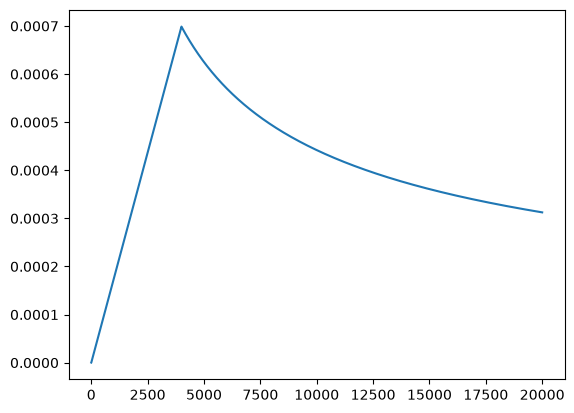

In [122]:
plt.plot([learning_rate(i, D_MODEL, 1.0, WARMUP_STEPS)
         for i in range(0, 20000)])

## Formatting the Data
We use `Dataset` and `DataLoader`. `Dataset` implements two methods: `__init__`, `__len__` and `__getitem__`. The last method returns an item of the dataset given an index. Using `collate_fn`, `DataLoader` returns a batch of `batch_size` samples.

In [123]:
from torch.utils.data import Dataset, DataLoader

In [124]:
class PairDataset(Dataset):
    def __init__(self, src_seqs, tgt_seqs,
                 token2idx):
        self.src_seqs = src_seqs
        self.tgt_seqs = tgt_seqs
        self.token2idx = token2idx

    def __len__(self):
        return len(self.src_seqs)

    def __getitem__(self, idx):
        src_batch = seqs2tensors([self.src_seqs[idx]],
                                 self.token2idx)
        tgt_batch = seqs2tensors([self.tgt_seqs[idx]],
                                 self.token2idx)

        return src_batch[0], tgt_batch[0]

    def collate(self, batch):
        src_batch, tgt_batch = list(zip(*batch))
        src_batch = pad_sequence(src_batch, batch_first=True,
                                 padding_value=0)
        tgt_batch = pad_sequence(tgt_batch, batch_first=True,
                                 padding_value=0)

        return src_batch, tgt_batch

In [125]:
train_dataset = PairDataset(train_src_seqs, train_tgt_seqs,
                            token2idx)
train_dataloader = DataLoader(train_dataset, batch_size=32,
                              shuffle=True,
                              collate_fn=train_dataset.collate)

In [126]:
val_dataset = PairDataset(val_src_seqs, val_tgt_seqs, token2idx)
val_dataloader = DataLoader(
    val_dataset, batch_size=32, collate_fn=val_dataset.collate)

## Training Loop

In [127]:
src_batch

tensor([[ 2, 30, 56,  ...,  0,  0,  0],
        [ 2, 48, 52,  ...,  0,  0,  0],
        [ 2, 48, 83,  ...,  0,  0,  0],
        ...,
        [ 2, 33, 56,  ...,  0,  0,  0],
        [ 2, 36, 52,  ...,  0,  0,  0],
        [ 2, 34, 52,  ...,  0,  0,  0]], device='cuda:0')

In [128]:
src_batch[:, 1:]

tensor([[30, 56, 71,  ...,  0,  0,  0],
        [48, 52, 69,  ...,  0,  0,  0],
        [48, 83, 63,  ...,  0,  0,  0],
        ...,
        [33, 56,  4,  ...,  0,  0,  0],
        [36, 52, 58,  ...,  0,  0,  0],
        [34, 52, 65,  ...,  0,  0,  0]], device='cuda:0')

In [129]:
translator = translator.to(DEVICE)

In [130]:
def evaluate(model, loss_fn, dataloader):
    model.eval()
    with torch.no_grad():
        t_loss = 0
        t_correct, t_chars = 0, 0
        for src_batch, tgt_batch in dataloader:
            src_batch = src_batch.to(DEVICE)
            tgt_batch = tgt_batch.to(DEVICE)
            tgt_input = tgt_batch[:, :-1]
            tgt_output = tgt_batch[:, 1:]
            src_padding_mask = (src_batch == 0)
            tgt_padding_mask = (tgt_input == 0).float()
            tgt_output_pred = model(src_batch, tgt_input,
                                    src_padding_mask,
                                    tgt_padding_mask)
            loss = loss_fn(
                tgt_output_pred.reshape(
                    -1,
                    tgt_output_pred.size(dim=-1)),
                tgt_output.reshape(-1))
            n_chars = (tgt_output != 0).sum()
            t_chars += n_chars
            t_loss += loss.item() * n_chars
            char_pred = torch.argmax(tgt_output_pred, dim=-1)
            char_correct = torch.mul((char_pred == tgt_output),
                                     (tgt_output != 0)).sum()
            t_correct += char_correct.item()
        return t_loss / t_chars, t_correct / t_chars

In [131]:
evaluate(translator, loss_fn, val_dataloader)

/home/lovis/anaconda3/lib/python3.14/site-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(


(tensor(8.4622, device='cuda:0'), tensor(0.0169, device='cuda:0'))

In [132]:
def train(model, loss_fn, optimizer, dataloader):
    model.train()
    t_loss = 0
    t_correct, t_chars = 0, 0
    for src_batch, tgt_batch in tqdm(dataloader):
        src_batch = src_batch.to(DEVICE)
        tgt_batch = tgt_batch.to(DEVICE)
        tgt_input = tgt_batch[:, :-1]
        tgt_output = tgt_batch[:, 1:]
        src_padding_mask = (src_batch == 0).to(DEVICE)
        tgt_padding_mask = (tgt_input == 0).float().to(DEVICE)
        tgt_output_pred = model(src_batch, tgt_input,
                                src_padding_mask,
                                tgt_padding_mask)
        optimizer.zero_grad()
        loss = loss_fn(
            tgt_output_pred.reshape(
                -1,
                tgt_output_pred.size(dim=-1)),
            tgt_output.reshape(-1))
        loss.backward()
        optimizer.step()
        lr_scheduler.step()
        with torch.no_grad():
            n_chars = (tgt_output != 0).sum()
            t_chars += n_chars
            t_loss += loss.item() * n_chars
            char_pred = torch.argmax(tgt_output_pred, dim=-1)
            char_correct = torch.mul((char_pred == tgt_output),
                                     (tgt_output != 0)).sum()
            t_correct += char_correct.item()

    return t_loss / t_chars, t_correct / t_chars

In [133]:
translator = torch.compile(translator)

About the loss. Overall, it should computed by individual prediction and divided by the number of chars. By default the crossentropy loss uses the mean. Then we use the mean of the mean. The trend is correct, but the values are not exact. A possible improvement would be to sum and pass through the mask.

In [134]:
EPOCHS = 80
history = {}
history['accuracy'] = []
history['loss'] = []
history['val_accuracy'] = []
history['val_loss'] = []

for epoch in range(EPOCHS):
    train_loss, train_acc = train(
        translator, loss_fn, optimizer, train_dataloader)
    history['loss'] += [train_loss.item()]
    history['accuracy'] += [train_acc.item()]
    val_loss, val_acc = evaluate(translator, loss_fn, val_dataloader)
    history['val_loss'] += [val_loss.item()]
    history['val_accuracy'] += [val_acc.item()]
    print((f"Epoch: {epoch}, Train loss: {train_loss:.3f}, Val loss: {val_loss:.3f}, Train acc.: {train_acc:.3f}, Val acc.: {val_acc:.3f}"))
    """
    if val_loss.item() <= min(history['val_loss']):
        torch.save(translator.state_dict(), MODEL_NAME)
        best_loss = val_loss.item()
        best_epoch = epoch
        print('Model saved')
    """
    if val_acc.item() >= max(history['val_accuracy']):
        torch.save(translator.state_dict(), MODEL_NAME)
        best_acc = val_acc.item()
        best_epoch = epoch
        print('Model saved')

  0%|          | 0/642 [00:00<?, ?it/s]

W1021 10:38:28.300000 9801 site-packages/torch/_dynamo/variables/tensor.py:1841] [0/0] Graph break from `Tensor.item()`, consider setting:
W1021 10:38:28.300000 9801 site-packages/torch/_dynamo/variables/tensor.py:1841] [0/0]     torch._dynamo.config.capture_scalar_outputs = True
W1021 10:38:28.300000 9801 site-packages/torch/_dynamo/variables/tensor.py:1841] [0/0] or:
W1021 10:38:28.300000 9801 site-packages/torch/_dynamo/variables/tensor.py:1841] [0/0]     env TORCHDYNAMO_CAPTURE_SCALAR_OUTPUTS=1
W1021 10:38:28.300000 9801 site-packages/torch/_dynamo/variables/tensor.py:1841] [0/0] to include these operations in the captured graph.
W1021 10:38:28.300000 9801 site-packages/torch/_dynamo/variables/tensor.py:1841] [0/0] 
W1021 10:38:28.300000 9801 site-packages/torch/_dynamo/variables/tensor.py:1841] [0/0] Graph break: from user code at:
W1021 10:38:28.300000 9801 site-packages/torch/_dynamo/variables/tensor.py:1841] [0/0]   File "/tmp/ipykernel_9801/2011274802.py", line 34, in forward


Epoch: 0, Train loss: 3.019, Val loss: 2.265, Train acc.: 0.303, Val acc.: 0.489
Model saved


100%|██████████| 642/642 [01:02<00:00, 10.28it/s]


Epoch: 1, Train loss: 2.175, Val loss: 1.985, Train acc.: 0.515, Val acc.: 0.588
Model saved


...

Epoch: 77, Train loss: 0.830, Val loss: 1.113, Train acc.: 0.981, Val acc.: 0.912
Model saved


100%|██████████| 642/642 [01:02<00:00, 10.34it/s]


Epoch: 78, Train loss: 0.829, Val loss: 1.116, Train acc.: 0.981, Val acc.: 0.912


100%|██████████| 642/642 [01:01<00:00, 10.36it/s]


Epoch: 79, Train loss: 0.828, Val loss: 1.115, Train acc.: 0.982, Val acc.: 0.912


## Plotting the Loss

In [135]:
epochs = range(EPOCHS)

In [136]:
history

{'accuracy': [0.30252355337142944,
  0.5151421427726746,
  0.5897831320762634,
  0.6347718834877014,
  0.665541410446167,
  0.6856608986854553,
  0.7036983966827393,
  0.7323263883590698,
  0.757805347442627,
  0.7792000770568848,
  0.7973268032073975,
  0.812248706817627,
  0.8259381055831909,
  0.8379580974578857,
  0.8477920293807983,
  0.8575125336647034,
  0.865186333656311,
  0.8732709288597107,
  0.880375862121582,
  0.8860680460929871,
  0.8925260305404663,
  0.8981178402900696,
  0.9032448530197144,
  0.9071727991104126,
  0.9116770625114441,
  0.9154804944992065,
  0.9194772839546204,
  0.9237509965896606,
  0.9261379241943359,
  0.9298986196517944,
  0.9323319792747498,
  0.9350386261940002,
  0.9382731914520264,
  0.9402455687522888,
  0.9422867298126221,
  0.944837212562561,
  0.9464377760887146,
  0.9487447738647461,
  0.9505014419555664,
  0.952380895614624,
  0.9537583589553833,
  0.9554147124290466,
  0.9573870301246643,
  0.9580023884773254,
  0.9595583081245422,
  0.

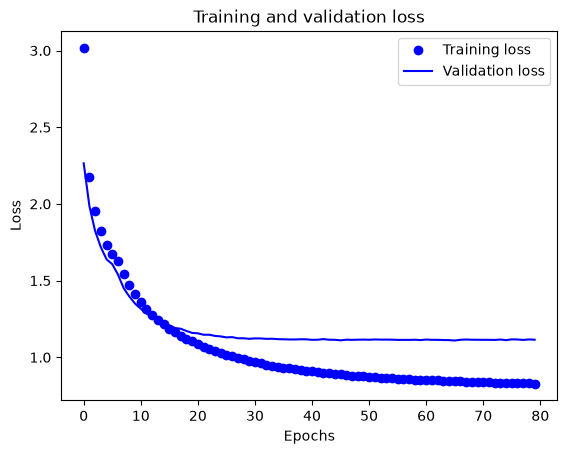

In [137]:
plt.plot(epochs, history['loss'], 'bo', label='Training loss')
plt.plot(epochs, history['val_loss'], 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

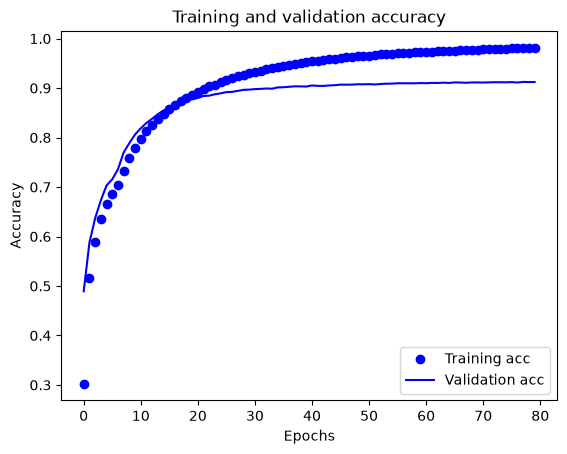

In [138]:
plt.plot(epochs, history['accuracy'], 'bo', label='Training acc')
plt.plot(epochs, history['val_accuracy'], 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## Application

In [139]:
def greedy_decode(model, src_seq, max_len):
    src_embs = model.embedding(src_seq)
    memory = model.transformer.encoder(src_embs)
    tgt_seq = torch.LongTensor([token2idx['<s>']]).to(DEVICE)
    tgt_embs = model.embedding(tgt_seq)
    max_len = min(max_len, MAX_LEN)

    for _ in range(max_len-1):
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(
            tgt_embs.size(dim=0), device=device)
        tgt_output = model.transformer.decoder(tgt_embs,
                                               memory,
                                               tgt_mask=tgt_mask)
        char_prob = model.fc(tgt_output[-1])
        next_char = torch.argmax(char_prob)
        tgt_seq = torch.cat(
            (tgt_seq,
             torch.unsqueeze(next_char, dim=0)), dim=0)
        tgt_embs = model.embedding(tgt_seq)
        if next_char.item() == token2idx['</s>']:  
            break
    return tgt_seq[1:]

`greedy_decode` with a batched input: `greedy_decode_batched`

In [140]:
def greedy_decode_batched(model, src_seq, max_len):
    src_seq = src_seq.unsqueeze(0) if src_seq.dim() == 1 else src_seq
    src_embs = model.embedding(src_seq)
    memory = model.transformer.encoder(src_embs)
    tgt_seq = torch.LongTensor([[token2idx['<s>']]]).to(DEVICE)
    tgt_embs = model.embedding(tgt_seq)
    max_len = min(max_len, MAX_LEN)

    for _ in range(max_len - 1):
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(
            tgt_embs.size(dim=1), device=device)
        tgt_output = model.transformer.decoder(
            tgt_embs, memory, tgt_mask=tgt_mask)
        char_prob = model.fc(tgt_output[:, -1, :])  
        next_char = torch.argmax(char_prob, dim=-1).unsqueeze(-1)
        tgt_seq = torch.cat((tgt_seq, next_char), dim=1)
        tgt_embs = model.embedding(tgt_seq)
        if next_char.item() == token2idx['</s>']:
            break
    return tgt_seq[0, 1:]

In [141]:
def translate(model, src_sentence, batched=True):
    model.eval()
    src = seqs2tensors([src_sentence.strip()], token2idx)[0].to(DEVICE)
    num_chars = src.size(dim=0)
    if batched:
        tgt_chars = greedy_decode_batched(
            model, src, max_len=num_chars + 20)
    else:
        tgt_chars = greedy_decode(
            model, src, max_len=num_chars + 20)
    tgt_chars = tensors2seqs([tgt_chars], idx2token)[0]
    if tgt_chars[-1] == '</s>':
        tgt_chars = tgt_chars[:-1]
    tgt_str = ''.join(tgt_chars)
    return tgt_str

In [142]:
tgt_sent = translate(translator, "jag älskar", batched=False)
tgt_sent

'I love you.'

In [143]:
tgt_sent = translate(
    translator, "godnatt", batched=False)
tgt_sent

'The cash endlessed.'

In [144]:
tgt_sent = translate(translator, "Redkalösköldsfklöte !", batched=False)
tgt_sent

'Really really forgive!'

## Save model

In [145]:

torch.save(translator.state_dict(), MODEL_NAME)

In [146]:
with open('pico_translator.vocab', 'w') as f:
    json.dump(token2idx, f)

## Evaluate the Model

In [147]:
model = Translator(d_model=D_MODEL,
                   nhead=NHEAD,
                   num_decoder_layers=NUM_ENCODER_LAYERS,
                   num_encoder_layers=NUM_DECODER_LAYERS,
                   dim_feedforward=DIM_FF,
                   vocab_size=VOCAB_SIZE,
                   max_len=MAX_LEN)

In [148]:
import numpy as np
import json
import torch

# Get the original model if torch.compile() wrapped it.
export_model = getattr(model, "_orig_mod", model)
export_model = export_model.cpu().eval()

# Export all parameters as NumPy arrays.
weights = {
    name: tensor.detach().cpu().numpy()
    for name, tensor in export_model.state_dict().items()
}

np.savez("translator_weights.npz", **weights)

# Export the exact character vocabulary used during training.
with open("translator_vocab.json", "w", encoding="utf-8") as f:
    json.dump(token2idx, f, ensure_ascii=False)

print("Exported translator_weights.npz")
print("Exported translator_vocab.json")

Exported translator_weights.npz
Exported translator_vocab.json


In [149]:
import json
import numpy as np

input_file = "translator_weights.npz"
output_file = "weights.bin"
manifest_file = "weights.json"

manifest = {}
offset = 0

with open(output_file, "wb") as out:
    with np.load(input_file) as archive:
        for name in archive.files:
            # Store all parameters as little-endian float32.
            arr = np.asarray(archive[name], dtype="<f4")
            arr = np.ascontiguousarray(arr)

            manifest[name] = {
                "shape": list(arr.shape),
                "offset": offset,
                "length": arr.size,
            }

            out.write(arr.tobytes(order="C"))
            offset += arr.size

with open(manifest_file, "w", encoding="utf-8") as f:
    json.dump(manifest, f)

print("Export complete")
print("Parameters:", len(manifest))
print("Binary size:", round(offset * 4 / 1024**2, 2), "MiB")




Export complete
Parameters: 98
Binary size: 84.79 MiB


In [150]:
model = torch.compile(model)

In [151]:

checkpoint = torch.load(MODEL_NAME)


In [152]:
model.load_state_dict(checkpoint)

<All keys matched successfully>

In [153]:
model.eval()

OptimizedModule(
  (_orig_mod): Translator(
    (embedding): Embedding(
      (input_embedding): Embedding(90, 512, padding_idx=0)
      (pos_embedding): Embedding(122, 512)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (encoder): TransformerEncoder(
        (layers): ModuleList(
          (0-2): 3 x TransformerEncoderLayer(
            (self_attn): MultiheadAttention(
              (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
            )
            (linear1): Linear(in_features=512, out_features=2048, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
            (linear2): Linear(in_features=2048, out_features=512, bias=True)
            (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
            (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
            (dropout1): Dropout(p=0.1, inplace=False)
            (dropout2): Dropout(

In [154]:
model.state_dict()

OrderedDict([('_orig_mod.embedding.input_embedding.weight',
              tensor([[-0.0040,  0.0120,  0.0014,  ..., -0.0134,  0.0075, -0.0119],
                      [-0.0016,  0.0141,  0.0035,  ..., -0.0108,  0.0097, -0.0092],
                      [-0.0165, -0.0106, -0.0134,  ..., -0.0690, -0.0147, -0.0533],
                      ...,
                      [-0.0008,  0.0141,  0.0033,  ..., -0.0119,  0.0076, -0.0117],
                      [-0.0130,  0.0221, -0.0055,  ..., -0.0278,  0.0130, -0.0106],
                      [ 0.0002,  0.0151,  0.0018,  ..., -0.0127,  0.0100, -0.0128]])),
             ('_orig_mod.embedding.pos_embedding.weight',
              tensor([[ 0.0000e+00,  1.0000e+00,  0.0000e+00,  ...,  1.0000e+00,
                        0.0000e+00,  1.0000e+00],
                      [ 8.4147e-01,  5.4030e-01,  8.2186e-01,  ...,  1.0000e+00,
                        1.0366e-04,  1.0000e+00],
                      [ 9.0930e-01, -4.1615e-01,  9.3641e-01,  ...,  1.0000e+00,
     

In [155]:
model = model.to(DEVICE)

In [156]:
translate(model, "hej")

'Shark.'

In [157]:
cand = []
for i, seq in tqdm(enumerate(val_src_seqs)):
    cand.append(translate(model, seq.strip()))
cand

5120it [06:36, 12.93it/s]


['We were anxious.',
 "We'll talk about it soon.",
 "We're all busy.",
 'The tower can see here.',
 'Birthds are expensive.',
 "There's nothing important than friends.",
 'The train was off time.',
 "They're stalling.",
 "They don't always obey their parents.",
 'Good afternoon.',
 "Tom doesn't hate you, Mary.",
 'The bus was almost empty.',
 'Just give us my minute.',
 'A lot of people were killed in the war.',
 'Tom almost went to be a car.',
 "Who's on the white water?",
 'Get me some wine.',
 'The debate has gone riden of the deep.',
 'We buried it.',
 "We're having fish.",
 'For the tall, there was a bridge here.',
 'They applauded.',
 'Tom arrived in time.',
 "She didn't come until two.",
 'He bought a shoe.',
 'Did you understand that?',
 'I learned French from my own.',
 'My nose itches.',
 "I'll get it.",
 "Do you think it'll rain today?",
 'How did you get in?',
 'Mary is pretty as her mother.',
 'My brother did it friends.',
 'This is all I want.',
 "In future, I'm being a g

In [114]:
bleu_score(cand, val_tgt_seqs)

tensor(0.4974)